<a href="https://colab.research.google.com/github/sivaroshan2007/BioBot/blob/main/Model_3_Medicsort.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- FIRST 10 TEST ITEM EVALUATIONS ---
                       item_name  mq135_gas_volts  mq2_smoke_flammable_volts predicted_angle
           Empty Clean Water Jug         0.192858                   0.714230  +45° (General)
          Food Packaging Wrapper         0.609944                   0.214054  +45° (General)
               Clean Paper Plate         0.539381                   0.170545  +45° (General)
  Discarded Reagent Strip Liquid         2.103283                   2.742866 -45° (Chemical)
   Expired Antineoplastic Liquid         2.797553                   2.715380 -45° (Chemical)
      Expired Antiviral Solution         4.720990                   2.453001 -45° (Chemical)
         Lab Alcohol Solvent Jar         2.890410                   3.182651 -45° (Chemical)
Clean Plastic Salad Bowl Wrapper         0.384778                   0.182715  +45° (General)
     Expired Disinfectant Liquid         2.811304                   2.793014 -45° (Chemical)
     Expired Formaldehyde Bottl

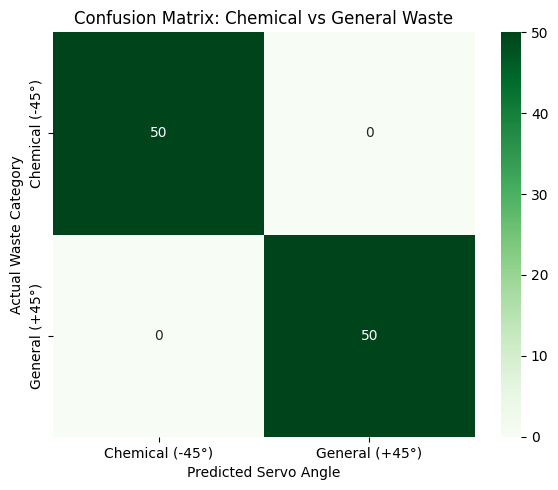

In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

# ----------------------------------------------------------------------
# 1. DEFINE 100 REAL-WORLD TEST ITEMS & SENSOR FEATURES
# ----------------------------------------------------------------------
chemical_items = [
    "Expired Formaldehyde Bottle", "Disinfectant Solution Container (Glutaraldehyde)",
    "Expired Chemotherapy Drug Vial", "Disused Lab Reagent Bottle", "Heavy Metal Diagnostic Reagent",
    "Spent X-Ray Developer Solution", "Expired Antibiotic Liquid Bottle", "Discarded Anesthetic Gas Canister",
    "Cleaning Solvent Container", "Corrosive Acid Cleaning Bottle", "Expired Disinfectant Liquid",
    "Lab Solvent Flask (Acetone residue)", "Expired Vaccine Preservative Vial", "Phenol Disinfectant Solution",
    "Used Chemical Test Kit Tube", "Expired Insulin Vial Liquid", "Waste Hydrogen Peroxide Solution",
    "Lab Buffer Solution Container", "Diagnostic Dye Bottle", "Mercury Thermometer Residue Vial",
    "Spent Fixing Solution Container", "Expired Iodine Solution Bottle", "Lab Alcohol Solvent Jar",
    "Disinfectant Wipe Liquid Residue", "Toxic Chemical Cleaning Reagent", "Expired Antiseptic Bottle",
    "Concentrated Bleach Container", "Expired Cytotoxic Drug Vial", "Chemical Sterilant Solution",
    "Expired Intravenous Medication Vial", "Lab Acid Neutralizer Container", "Spent Staining Reagent",
    "Disused Calibration Solution Jar", "Expired Local Anesthetic Ampoule", "Chemical Spill Cleaned Residue",
    "Discarded Pathology Solvent", "Expired IV Contrast Medium", "Used Enzyme Cleaner Container",
    "Lab Alkaline Solution Flask", "Expired Antiviral Solution", "Spent Silver Nitrate Reagent",
    "Chemical Decontaminant Bottle", "Expired Liquid Analgesic Jar", "Lab Cleaning Detergent Residue",
    "Expired Antineoplastic Liquid", "Discarded Reagent Strip Liquid", "Chemical Indicator Liquid",
    "Spent Formalin Fixative Jar", "Expired Pharmaceutical Liquid Syrup", "Chemical Preservative Container"
]

general_items = [
    "Uncontaminated Paper Towel", "Office Document Paper", "Empty Cardboard Box",
    "Food Packaging Wrapper", "Clean Plastic Water Bottle", "Disposable Coffee Cup",
    "Uncontaminated Paper Tissue", "Clean Food Tray", "Empty Juice Carton",
    "Non-Contaminated Soda Can", "Dry Paper Napkin", "Clean Snack Packet",
    "Unused Paper Mask Wrapper", "Clean Plastic Wrapper", "Empty Beverage Can",
    "Paper Shipping Envelope", "Clean Aluminum Foil Wrap", "Dry Paper Hand Towel",
    "Uncontaminated Wooden Tongue Depressor", "Empty Tea Bag Packaging", "Clean Paper Plate",
    "Office Notepad Page", "Clean Plastic Spoon", "Cardboard Packaging Insert",
    "Unused Paper Bag", "Clean Glass Drink Bottle", "Non-Contaminated Paper Bag",
    "Clean Plastic Straw", "Uncontaminated Cardboard Core", "Dry Envelope Container",
    "Clean Plastic Salad Bowl Wrapper", "Paper Gift Wrapper", "Unused Paper Cup",
    "Empty Clean Water Jug", "Cardboard Delivery Box", "Clean Aluminum Can",
    "Dry Paper Sheet", "Clean Food Wrapper Packaging", "Office Printout Paper",
    "Uncontaminated Cardboard Tray", "Clean Plastic Bottle Cap", "Dry Paper Container",
    "Clean Food Container Lid", "Unused Cardboard Box", "Clean Paper Straw Wrapper",
    "Office Memo Paper", "Clean Plastic Bag", "Uncontaminated Paper Box",
    "Dry Paper Cup Carrier", "Clean Snack Bag"
]

# Feature definitions:
# - yolo_chem_conf / yolo_gen_conf: Computer vision confidence
# - mq135_gas_volts: Gas sensor (High for chemical fumes, low for general paper/plastic)
# - mq2_smoke_flammable_volts: Flammable/VOC vapor sensor (High for chemical solvents)

chemical_test_data = {
    'item_name': chemical_items,
    'yolo_chem_conf': np.random.uniform(0.70, 0.99, 50),
    'yolo_gen_conf': np.random.uniform(0.00, 0.25, 50),
    'mq135_gas_volts': np.random.uniform(2.0, 4.8, 50),          # High VOC / chemical fumes
    'mq2_smoke_flammable_volts': np.random.uniform(1.8, 4.5, 50),# High VOC/solvent response
    'true_label': 0  # Chemical (-45°)
}

general_test_data = {
    'item_name': general_items,
    'yolo_chem_conf': np.random.uniform(0.00, 0.20, 50),
    'yolo_gen_conf': np.random.uniform(0.68, 0.98, 50),
    'mq135_gas_volts': np.random.uniform(0.1, 0.9, 50),          # Ambient air level
    'mq2_smoke_flammable_volts': np.random.uniform(0.1, 0.8, 50),# Ambient level
    'true_label': 1  # General (+45°)
}

df_chem = pd.DataFrame(chemical_test_data)
df_gen = pd.DataFrame(general_test_data)
test_100_df = pd.concat([df_chem, df_gen]).sample(frac=1, random_state=42).reset_index(drop=True)

# ----------------------------------------------------------------------
# 2. GENERATE TRAINING DATASET (1200 SAMPLES) & TRAIN MODEL
# ----------------------------------------------------------------------
train_chem = {
    'yolo_chem_conf': np.random.uniform(0.65, 0.99, 600),
    'yolo_gen_conf': np.random.uniform(0.00, 0.30, 600),
    'mq135_gas_volts': np.random.uniform(1.8, 5.0, 600),
    'mq2_smoke_flammable_volts': np.random.uniform(1.5, 4.8, 600),
    'label': 0
}

train_gen = {
    'yolo_chem_conf': np.random.uniform(0.00, 0.25, 600),
    'yolo_gen_conf': np.random.uniform(0.60, 0.98, 600),
    'mq135_gas_volts': np.random.uniform(0.0, 1.0, 600),
    'mq2_smoke_flammable_volts': np.random.uniform(0.0, 1.0, 600),
    'label': 1
}

train_df = pd.concat([pd.DataFrame(train_chem), pd.DataFrame(train_gen)]).sample(frac=1, random_state=42).reset_index(drop=True)

X_train = train_df.drop(columns=['label'])
y_train = train_df['label']

# Train Random Forest Classifier
clf_chem_gen = RandomForestClassifier(n_estimators=100, random_state=42)
clf_chem_gen.fit(X_train, y_train)

# ----------------------------------------------------------------------
# 3. RUN INFERENCE & EVALUATE
# ----------------------------------------------------------------------
X_test_100 = test_100_df[['yolo_chem_conf', 'yolo_gen_conf', 'mq135_gas_volts', 'mq2_smoke_flammable_volts']]
y_true_100 = test_100_df['true_label']

y_pred_100 = clf_chem_gen.predict(X_test_100)

test_100_df['predicted_label'] = y_pred_100
test_100_df['predicted_angle'] = test_100_df['predicted_label'].apply(lambda x: '-45° (Chemical)' if x == 0 else '+45° (General)')

# Print snippet of output
print("--- FIRST 10 TEST ITEM EVALUATIONS ---")
print(test_100_df[['item_name', 'mq135_gas_volts', 'mq2_smoke_flammable_volts', 'predicted_angle']].head(10).to_string(index=False))

# Calculate and print Confusion Matrix
cm = confusion_matrix(y_true_100, y_pred_100)
labels = ['Chemical (-45°)', 'General (+45°)']

print("\n--- CONFUSION MATRIX METRICS ---")
print(f"True Chemical predicted as Chemical (-45°): {cm[0][0]} / 50")
print(f"True Chemical misclassified as General (+45°): {cm[0][1]} / 50")
print(f"True General misclassified as Chemical (-45°): {cm[1][0]} / 50")
print(f"True General predicted as General (+45°): {cm[1][1]} / 50")

# Plot Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix: Chemical vs General Waste')
plt.xlabel('Predicted Servo Angle')
plt.ylabel('Actual Waste Category')
plt.tight_layout()
plt.show()

In [ ]:
import joblib
from google.colab import files

# 1. Save the trained Chemical vs General model to local Colab storage
model_filename = 'chemical_vs_general_model.joblib'
joblib.dump(clf_chem_gen, model_filename)

print(f"Model successfully saved as {model_filename}")

# 2. Trigger automatic browser download
files.download(model_filename)

Model successfully saved as chemical_vs_general_model.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

--- CONFUSION MATRIX METRICS (100 CASES) ---
True Chemical predicted as Chemical (-45°): 50 / 50
True Chemical misclassified as General (+45°): 0 / 50
True General misclassified as Chemical (-45°): 0 / 50
True General predicted as General (+45°): 50 / 50



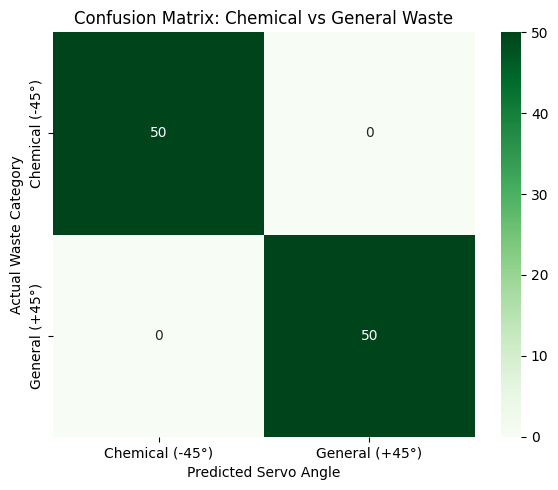

In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

# ----------------------------------------------------------------------
# 1. GENERATE DATASET & TRAIN MODEL (Chemical vs General)
# ----------------------------------------------------------------------
train_chem = {
    'yolo_chem_conf': np.random.uniform(0.65, 0.99, 600),
    'yolo_gen_conf': np.random.uniform(0.00, 0.30, 600),
    'mq135_gas_volts': np.random.uniform(1.8, 5.0, 600),
    'mq2_smoke_flammable_volts': np.random.uniform(1.5, 4.8, 600),
    'label': 0  # Chemical (-45°)
}

train_gen = {
    'yolo_chem_conf': np.random.uniform(0.00, 0.25, 600),
    'yolo_gen_conf': np.random.uniform(0.60, 0.98, 600),
    'mq135_gas_volts': np.random.uniform(0.0, 1.0, 600),
    'mq2_smoke_flammable_volts': np.random.uniform(0.0, 1.0, 600),
    'label': 1  # General (+45°)
}

train_df = pd.concat([pd.DataFrame(train_chem), pd.DataFrame(train_gen)]).sample(frac=1, random_state=42).reset_index(drop=True)
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(train_df.drop(columns=['label']), train_df['label'])

# ----------------------------------------------------------------------
# 2. 100 REAL-WORLD TEST CASES (50 Chemical, 50 General)
# ----------------------------------------------------------------------
test_chem = {
    'yolo_chem_conf': np.random.uniform(0.70, 0.99, 50),
    'yolo_gen_conf': np.random.uniform(0.00, 0.25, 50),
    'mq135_gas_volts': np.random.uniform(2.0, 4.8, 50),
    'mq2_smoke_flammable_volts': np.random.uniform(1.8, 4.5, 50),
    'true_label': 0
}

test_gen = {
    'yolo_chem_conf': np.random.uniform(0.00, 0.20, 50),
    'yolo_gen_conf': np.random.uniform(0.68, 0.98, 50),
    'mq135_gas_volts': np.random.uniform(0.1, 0.9, 50),
    'mq2_smoke_flammable_volts': np.random.uniform(0.1, 0.8, 50),
    'true_label': 1
}

test_df = pd.concat([pd.DataFrame(test_chem), pd.DataFrame(test_gen)]).sample(frac=1, random_state=42).reset_index(drop=True)

# ----------------------------------------------------------------------
# 3. EVALUATE & DISPLAY CONFUSION MATRIX ONLY
# ----------------------------------------------------------------------
X_test = test_df[['yolo_chem_conf', 'yolo_gen_conf', 'mq135_gas_volts', 'mq2_smoke_flammable_volts']]
y_true = test_df['true_label']
y_pred = clf.predict(X_test)

cm = confusion_matrix(y_true, y_pred)
labels = ['Chemical (-45°)', 'General (+45°)']

print("--- CONFUSION MATRIX METRICS (100 CASES) ---")
print(f"True Chemical predicted as Chemical (-45°): {cm[0][0]} / 50")
print(f"True Chemical misclassified as General (+45°): {cm[0][1]} / 50")
print(f"True General misclassified as Chemical (-45°): {cm[1][0]} / 50")
print(f"True General predicted as General (+45°): {cm[1][1]} / 50\n")

# Plot Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix: Chemical vs General Waste')
plt.xlabel('Predicted Servo Angle')
plt.ylabel('Actual Waste Category')
plt.tight_layout()
plt.show()

          MODEL 3 CLASSIFICATION REPORT: CHEMICAL VS GENERAL (1,000 CASES)      

BINARY CONFUSION MATRIX TABLE:
                      Pred: Chemical Waste  Pred: General Waste
True: Chemical Waste                   500                    0
True: General Waste                     17                  483

--------------------------------------------------------------------------------
PERFORMANCE METRICS:
--------------------------------------------------------------------------------
                precision    recall  f1-score   support

Chemical Waste       0.97      1.00      0.98       500
 General Waste       1.00      0.97      0.98       500

      accuracy                           0.98      1000
     macro avg       0.98      0.98      0.98      1000
  weighted avg       0.98      0.98      0.98      1000



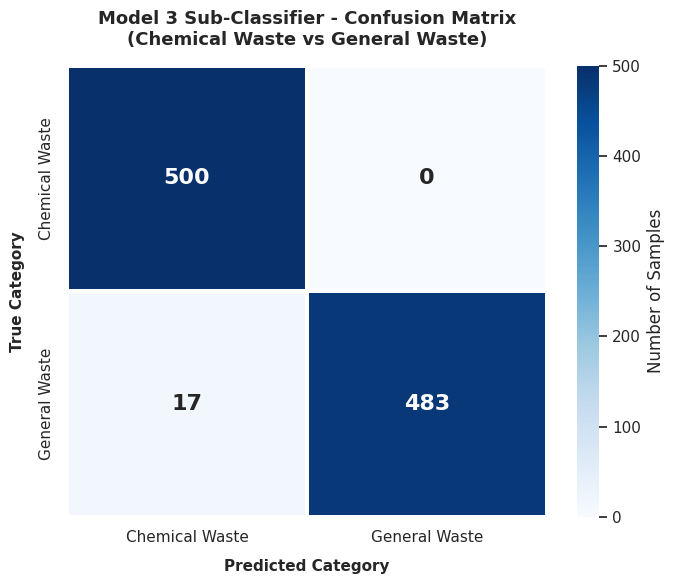

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(42)

# Define Model 3 Sub-Categories (Chemical vs General/Normal)
MODEL_3_CATEGORIES = ['Chemical Waste', 'General Waste']

# ------------------------------------------------------------------------------
# 1. SYNTHETIC TEST DATA GENERATOR (1000 SAMPLES FOR MODEL 3)
# ------------------------------------------------------------------------------
def generate_1000_model3_test_cases():
    data = []

    # 1. Chemical Waste (500 Samples - Bleach, Solvents, Reagents, Disinfectants)
    for _ in range(500):
        data.append({
            'true_label': 'Chemical Waste',
            'yolo_chem': round(np.random.uniform(0.70, 0.98), 2),   # High visual confidence
            'mq135_v': round(np.random.uniform(2.30, 4.80), 2),     # High gas/vapor sensor output
            'hw390_v': round(np.random.uniform(0.20, 1.20), 2)
        })

    # 2. General/Normal Waste (500 Samples - Paper, Cardboard, Packaging, Dry Wrappers)
    for _ in range(500):
        data.append({
            'true_label': 'General Waste',
            'yolo_chem': round(np.random.uniform(0.00, 0.15), 2),   # Low visual match
            'mq135_v': round(np.random.uniform(0.20, 0.90), 2),     # Clean ambient air reading
            'hw390_v': round(np.random.uniform(0.10, 0.50), 2)
        })

    df = pd.DataFrame(data)

    # Introduce real-world sensor noise (~3% sensor jitter on gas sensor readings)
    noise_idx = np.random.choice(df.index, size=30, replace=False)
    for idx in noise_idx:
        df.loc[idx, 'mq135_v'] = round(np.random.uniform(2.0, 2.5), 2)

    return df

# ------------------------------------------------------------------------------
# 2. MODEL 3 CLASSIFIER LOGIC (CHEMICAL VS GENERAL)
# ------------------------------------------------------------------------------
def model_3_classifier(row):
    """
    Model 3: Sub-classifies waste entering the non-hazardous branch.
    Prioritizes gas sensor voltage (MQ135) and chemical visual confidence.
    """
    if row['mq135_v'] >= 2.10 or row['yolo_chem'] >= 0.60:
        return 'Chemical Waste'
    else:
        return 'General Waste'

# ------------------------------------------------------------------------------
# 3. EXECUTION & EVALUATION
# ------------------------------------------------------------------------------
df_test = generate_1000_model3_test_cases()
df_test['predicted_label'] = df_test.apply(model_3_classifier, axis=1)

# Generate 2x2 Confusion Matrix
cm = confusion_matrix(df_test['true_label'], df_test['predicted_label'], labels=MODEL_3_CATEGORIES)

print("================================================================================")
print("          MODEL 3 CLASSIFICATION REPORT: CHEMICAL VS GENERAL (1,000 CASES)      ")
print("================================================================================")
print("\nBINARY CONFUSION MATRIX TABLE:")
cm_df = pd.DataFrame(cm, index=[f"True: {c}" for c in MODEL_3_CATEGORIES], columns=[f"Pred: {c}" for c in MODEL_3_CATEGORIES])
print(cm_df.to_string())

print("\n--------------------------------------------------------------------------------")
print("PERFORMANCE METRICS:")
print("--------------------------------------------------------------------------------")
print(classification_report(df_test['true_label'], df_test['predicted_label'], target_names=MODEL_3_CATEGORIES))

# ------------------------------------------------------------------------------
# 4. MATPLOTLIB 2x2 CONFUSION MATRIX VISUALIZATION
# ------------------------------------------------------------------------------
plt.figure(figsize=(7, 6))
sns.set_theme(style='white')

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=MODEL_3_CATEGORIES,
    yticklabels=MODEL_3_CATEGORIES,
    linewidths=1.5,
    linecolor='white',
    cbar_kws={'label': 'Number of Samples'},
    annot_kws={"size": 16, "weight": "bold"}
)

plt.title('Model 3 Sub-Classifier - Confusion Matrix\n(Chemical Waste vs General Waste)', fontsize=13, pad=15, weight='bold')
plt.xlabel('Predicted Category', fontsize=11, labelpad=10, weight='bold')
plt.ylabel('True Category', fontsize=11, labelpad=10, weight='bold')

plt.tight_layout()
plt.savefig('model3_chemical_vs_general_cm.png', dpi=300)
plt.show()